# Notebook 61 — Small image-generation comparison

This notebook compares two deliberately small image generators:

- a convolutional GAN, which generates an image in one forward pass;
- a rectified-flow model, which gradually transports random noise toward the data distribution.

The goal is intuition rather than state-of-the-art image quality. We use Fashion-MNIST resized to 16 × 16 so both models train in a reasonable time. All implementation cells are complete: run the notebook from top to bottom, inspect the curves and images, and then record your observations in the reflection section.

The first run downloads Fashion-MNIST into the local data directory. Later runs reuse the cached files.

In [1]:
from __future__ import annotations

import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cs231n_practice.generative import (
    gan_discriminator_step,
    gan_generator_step,
    rectified_flow_training_step,
    sample_latent,
    sample_rectified_flow,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

IMAGE_SIZE = 16
DATA_DIM = IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 64
TRAIN_SAMPLES = 12_000
BATCH_SIZE = 128
GAN_EPOCHS = 10
FLOW_EPOCHS = 10
FLOW_SAMPLING_STEPS = 30
SENSITIVITY_EPOCHS = 6

print(f"device: {DEVICE}")
print(f"PyTorch: {torch.__version__}")

device: mps
PyTorch: 2.13.0


## 1. Dataset and representation

Fashion-MNIST contains grayscale clothing images. We resize each 28 × 28 image to 16 × 16 and map pixel values from [0, 1] to [-1, 1].

The GAN generator ends with tanh, so its output uses the same range. The flow model also learns trajectories whose data endpoint lies in this range. For display we convert values back to [0, 1].

We train on a fixed 12,000-image subset. This keeps the experiment approachable, but it also limits image quality and makes instability easier to observe.

In [2]:
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

full_training_dataset = datasets.FashionMNIST(
    root=PROJECT_ROOT / "data",
    train=True,
    transform=image_transform,
    download=True,
)

subset_generator = torch.Generator().manual_seed(SEED)
subset_indices = torch.randperm(
    len(full_training_dataset),
    generator=subset_generator,
)[:TRAIN_SAMPLES]

training_dataset = Subset(full_training_dataset, subset_indices.tolist())
loader_generator = torch.Generator().manual_seed(SEED)
training_loader = DataLoader(
    training_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)

class_names = full_training_dataset.classes
print(f"training samples: {len(training_dataset):,}")
print(f"classes: {class_names}")

training samples: 12,000
classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


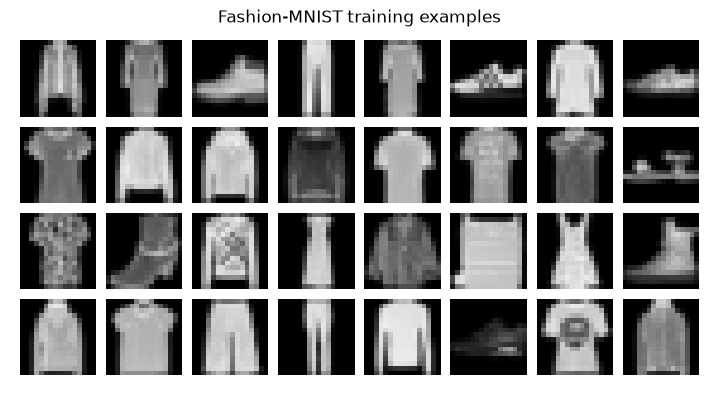

batch image shape: (128, 1, 16, 16)
batch label shape: (128,)


In [3]:
def show_image_grid(images, title, *, rows=4, columns=8):
    """Display flattened or NCHW grayscale images in a fixed-size grid."""
    images = images.detach().cpu()
    if images.ndim == 2:
        images = images.reshape(-1, 1, IMAGE_SIZE, IMAGE_SIZE)
    images = ((images + 1.0) / 2.0).clamp(0.0, 1.0)
    images = images[: rows * columns]

    grid = make_grid(images, nrow=columns, padding=2, pad_value=1.0)
    plt.figure(figsize=(columns * 1.15, rows * 1.15))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray", vmin=0.0, vmax=1.0)
    plt.title(title)
    plt.axis("off")
    plt.show()


real_images, real_labels = next(iter(training_loader))
show_image_grid(real_images, "Fashion-MNIST training examples")
print("batch image shape:", tuple(real_images.shape))
print("batch label shape:", tuple(real_labels.shape))

## 2. Models

The two generators solve different learning problems.

The GAN generator maps one latent vector directly to one image. Its discriminator learns to distinguish real images from generated images, while the generator learns to fool the discriminator.

The rectified-flow model receives a noisy image state and a time value. It predicts a velocity: a direction in image space that should move the current state toward the data distribution. Generation repeatedly applies this learned direction, so it requires many model evaluations.

In [4]:
from cs231n_practice.classifiers import (
    ConvolutionalDiscriminator,
    ConvolutionalGenerator,
    SmallImageVelocityNet,
)

# These reusable models keep the architectural details in the package while
# this notebook focuses on training, comparison, and visualization.
gan_generator = ConvolutionalGenerator(
    latent_dim=LATENT_DIM,
    image_size=IMAGE_SIZE,
).to(DEVICE)
gan_discriminator = ConvolutionalDiscriminator(
    image_size=IMAGE_SIZE,
).to(DEVICE)
flow_model = SmallImageVelocityNet(
    image_size=IMAGE_SIZE,
).to(DEVICE)


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


print(f"GAN generator parameters:     {count_parameters(gan_generator):,}")
print(f"GAN discriminator parameters: {count_parameters(gan_discriminator):,}")
print(f"Flow model parameters:        {count_parameters(flow_model):,}")

GAN generator parameters:     100,065
GAN discriminator parameters: 34,401
Flow model parameters:        144,385


## 3. Train the convolutional GAN

GAN training alternates between two objectives:

1. the discriminator increases its ability to separate real and generated images;
2. the generator changes its samples so the discriminator classifies them as real.

The loss curves need not decrease smoothly together. The two networks are opponents, so improvement by one changes the task faced by the other. Generated snapshots are usually more informative than either loss alone.

In [5]:
@torch.no_grad()
def generate_gan_images(generator, latent_vectors):
    generator.eval()
    return generator(latent_vectors).reshape(-1, 1, IMAGE_SIZE, IMAGE_SIZE).cpu()


def train_image_gan(
    generator,
    discriminator,
    data_loader,
    *,
    epochs,
    generator_learning_rate=2e-4,
    discriminator_learning_rate=2e-4,
):
    generator_optimizer = torch.optim.Adam(
        generator.parameters(),
        lr=generator_learning_rate,
        betas=(0.5, 0.999),
    )
    discriminator_optimizer = torch.optim.Adam(
        discriminator.parameters(),
        lr=discriminator_learning_rate,
        betas=(0.5, 0.999),
    )

    fixed_latent = sample_latent(
        32,
        LATENT_DIM,
        device=DEVICE,
        dtype=next(generator.parameters()).dtype,
    )
    history = {"generator": [], "discriminator": []}
    snapshots = {0: generate_gan_images(generator, fixed_latent)}
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        generator.train()
        discriminator.train()
        generator_losses = []
        discriminator_losses = []

        for images, _ in data_loader:
            real_vectors = images.to(DEVICE).flatten(start_dim=1)

            discriminator_latent = sample_latent(
                real_vectors.shape[0], LATENT_DIM, device=DEVICE
            )
            discriminator_loss = gan_discriminator_step(
                generator,
                discriminator,
                discriminator_optimizer,
                real_vectors,
                discriminator_latent,
            )
            generator_latent = sample_latent(
                real_vectors.shape[0], LATENT_DIM, device=DEVICE
            )
            generator_loss = gan_generator_step(
                generator,
                discriminator,
                generator_optimizer,
                generator_latent,
            )
            # Move scalar losses from the accelerator to ordinary Python
            # numbers before NumPy calculates the epoch average.
            discriminator_losses.append(discriminator_loss.item())
            generator_losses.append(generator_loss.item())

        history["discriminator"].append(float(np.mean(discriminator_losses)))
        history["generator"].append(float(np.mean(generator_losses)))
        snapshots[epoch] = generate_gan_images(generator, fixed_latent)
        print(
            f"GAN epoch {epoch:02d}/{epochs}: "
            f"D={history['discriminator'][-1]:.4f}, "
            f"G={history['generator'][-1]:.4f}"
        )

    return history, snapshots, time.perf_counter() - started


gan_history, gan_snapshots, gan_training_seconds = train_image_gan(
    gan_generator,
    gan_discriminator,
    training_loader,
    epochs=GAN_EPOCHS,
)

print(f"GAN training time: {gan_training_seconds:.1f} seconds")

GAN epoch 01/10: D=0.8863, G=1.1705
GAN epoch 02/10: D=0.9329, G=1.1656
GAN epoch 03/10: D=1.2425, G=0.9312
GAN epoch 04/10: D=1.2295, G=0.8144
GAN epoch 05/10: D=1.2758, G=0.7621
GAN epoch 06/10: D=1.2741, G=0.7640
GAN epoch 07/10: D=1.2525, G=0.7851
GAN epoch 08/10: D=1.2742, G=0.7748
GAN epoch 09/10: D=1.2795, G=0.7758
GAN epoch 10/10: D=1.2564, G=0.7901
GAN training time: 15.1 seconds


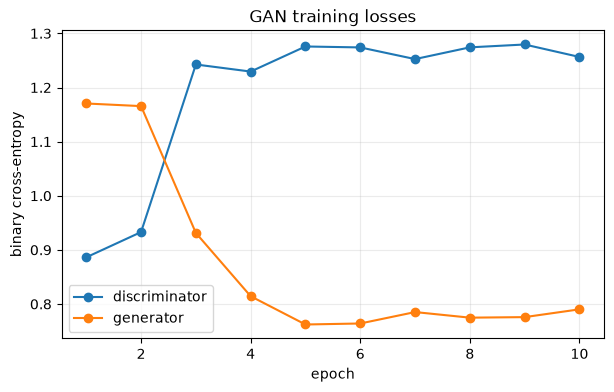

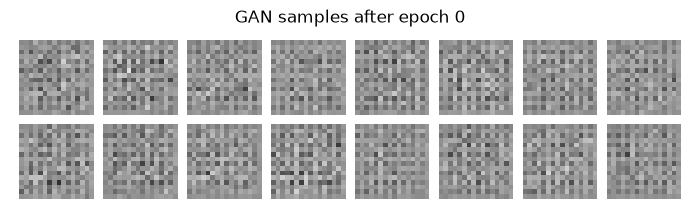

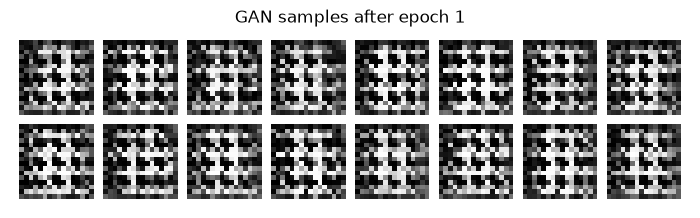

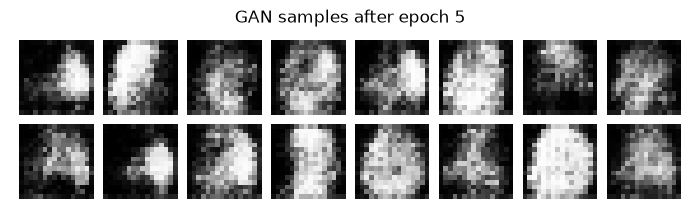

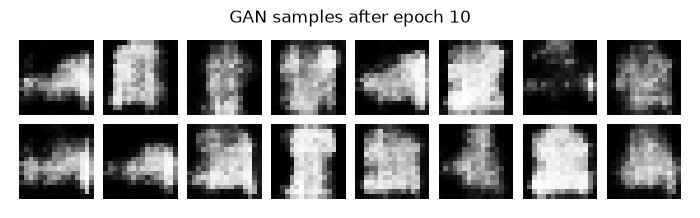

In [6]:
epochs = np.arange(1, GAN_EPOCHS + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, gan_history["discriminator"], marker="o", label="discriminator")
plt.plot(epochs, gan_history["generator"], marker="o", label="generator")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy")
plt.title("GAN training losses")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

snapshot_epochs = sorted({0, 1, max(1, GAN_EPOCHS // 2), GAN_EPOCHS})
for epoch in snapshot_epochs:
    show_image_grid(
        gan_snapshots[epoch],
        f"GAN samples after epoch {epoch}",
        rows=2,
        columns=8,
    )

## 4. Train the rectified-flow model

For every training image x_data, we draw noise x_noise and a time t. The interpolated state is

x_t = (1 - t) x_noise + t x_data.

The target velocity is x_data - x_noise: the constant direction from that noise sample to that data sample. The network learns to estimate this direction from only x_t and t.

At generation time we begin with new Gaussian noise and numerically integrate the learned velocity field from t = 0 to t = 1. More integration steps are slower but usually approximate the trajectory more accurately.

In [7]:
@torch.no_grad()
def generate_flow_images(model, initial_noise, *, steps=FLOW_SAMPLING_STEPS):
    generated, _ = sample_rectified_flow(model, initial_noise, steps)
    return generated.reshape(-1, 1, IMAGE_SIZE, IMAGE_SIZE).cpu()


def train_image_flow(model, data_loader, *, epochs, learning_rate=2e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    fixed_noise = torch.randn(32, DATA_DIM, device=DEVICE)
    history = []
    snapshots = {
        0: fixed_noise.reshape(-1, 1, IMAGE_SIZE, IMAGE_SIZE).cpu()
    }
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        losses = []
        for images, _ in data_loader:
            real_vectors = images.to(DEVICE).flatten(start_dim=1)
            loss = rectified_flow_training_step(model, optimizer, real_vectors)
            # NumPy cannot directly read a tensor stored on MPS or CUDA.
            losses.append(loss.item())

        history.append(float(np.mean(losses)))
        snapshots[epoch] = generate_flow_images(model, fixed_noise)
        print(f"Flow epoch {epoch:02d}/{epochs}: MSE={history[-1]:.4f}")

    return history, snapshots, time.perf_counter() - started


flow_history, flow_snapshots, flow_training_seconds = train_image_flow(
    flow_model,
    training_loader,
    epochs=FLOW_EPOCHS,
)

print(f"Flow training time: {flow_training_seconds:.1f} seconds")

Flow epoch 01/10: MSE=1.2970
Flow epoch 02/10: MSE=0.8724
Flow epoch 03/10: MSE=0.6800
Flow epoch 04/10: MSE=0.5945
Flow epoch 05/10: MSE=0.5547
Flow epoch 06/10: MSE=0.5220
Flow epoch 07/10: MSE=0.5032
Flow epoch 08/10: MSE=0.4785
Flow epoch 09/10: MSE=0.4658
Flow epoch 10/10: MSE=0.4464
Flow training time: 19.1 seconds


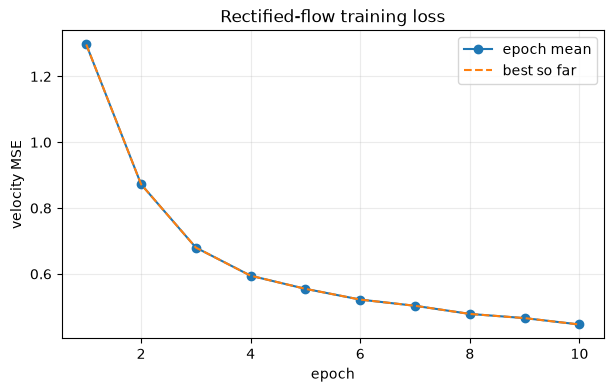

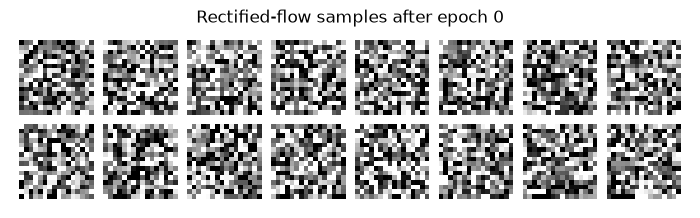

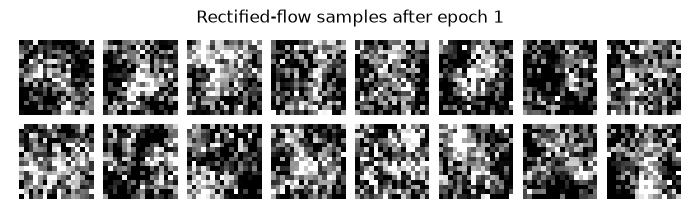

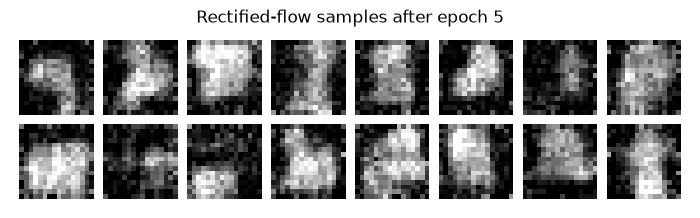

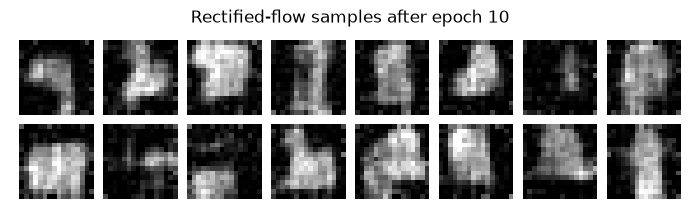

In [8]:
epochs = np.arange(1, FLOW_EPOCHS + 1)
best_so_far = np.minimum.accumulate(flow_history)

plt.figure(figsize=(7, 4))
plt.plot(epochs, flow_history, marker="o", label="epoch mean")
plt.plot(epochs, best_so_far, linestyle="--", label="best so far")
plt.xlabel("epoch")
plt.ylabel("velocity MSE")
plt.title("Rectified-flow training loss")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

snapshot_epochs = sorted({0, 1, max(1, FLOW_EPOCHS // 2), FLOW_EPOCHS})
for epoch in snapshot_epochs:
    show_image_grid(
        flow_snapshots[epoch].clamp(-1.0, 1.0),
        f"Rectified-flow samples after epoch {epoch}",
        rows=2,
        columns=8,
    )

## 5. Final samples and simple diversity indicators

Visual inspection should ask two separate questions:

- recognizability: do samples resemble clothing items?
- diversity: do samples differ from one another, or has a model repeated a few patterns?

The numerical indicators below measure spread, not perceptual quality:

- mean pixel standard deviation measures variation at corresponding pixel locations;
- mean pairwise distance measures average separation between generated image vectors.

A generator can score highly by producing noisy images, so these are not replacements for visual inspection or metrics such as FID (Fréchet Inception Distance).

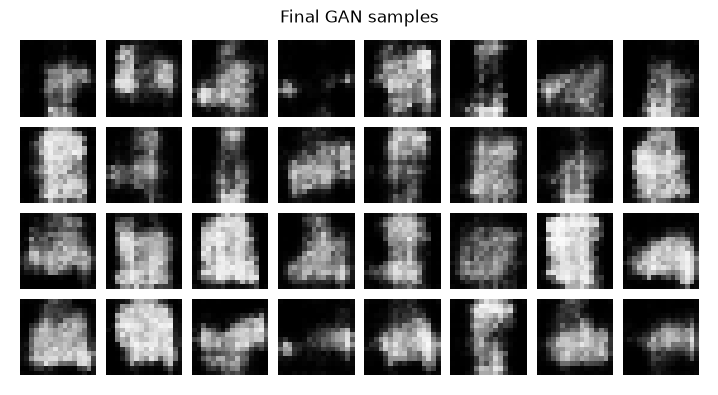

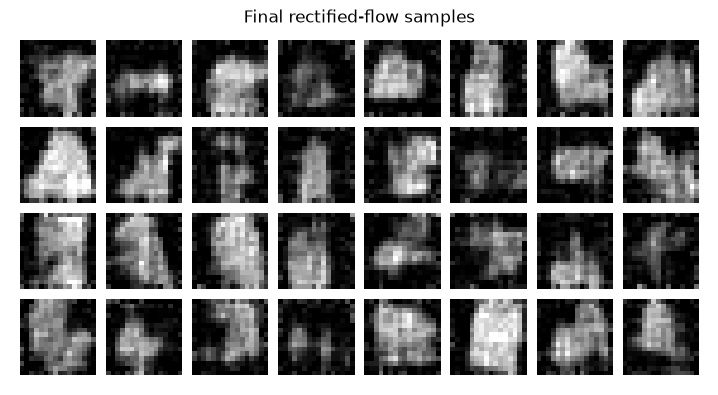

GAN  — mean pixel std: 0.433, mean pairwise distance: 10.545
Flow — mean pixel std: 0.432, mean pairwise distance: 10.073


In [9]:
evaluation_latent = sample_latent(64, LATENT_DIM, device=DEVICE)
evaluation_noise = torch.randn(64, DATA_DIM, device=DEVICE)

gan_samples = generate_gan_images(gan_generator, evaluation_latent)
flow_samples = generate_flow_images(
    flow_model,
    evaluation_noise,
    steps=FLOW_SAMPLING_STEPS,
).clamp(-1.0, 1.0)

show_image_grid(gan_samples, "Final GAN samples", rows=4, columns=8)
show_image_grid(flow_samples, "Final rectified-flow samples", rows=4, columns=8)


def diversity_summary(images):
    """Return two simple spread statistics for a generated image batch."""
    flat = images.flatten(start_dim=1).float()
    mean_pixel_standard_deviation = flat.std(dim=0).mean().item()
    mean_pairwise_distance = torch.pdist(flat).mean().item()
    return mean_pixel_standard_deviation, mean_pairwise_distance


gan_diversity = diversity_summary(gan_samples)
flow_diversity = diversity_summary(flow_samples)

print(
    "GAN  — mean pixel std: "
    f"{gan_diversity[0]:.3f}, mean pairwise distance: {gan_diversity[1]:.3f}"
)
print(
    "Flow — mean pixel std: "
    f"{flow_diversity[0]:.3f}, mean pairwise distance: {flow_diversity[1]:.3f}"
)

## 6. Generation speed

A GAN generator produces a batch with one forward pass. Rectified flow invokes its network once per integration step. Therefore flow generation is expected to be slower even when its individual network is small.

The exact timing depends on the device and includes framework overhead, so compare the order of magnitude rather than treating one run as a benchmark.

In [10]:
def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


timing_batch_size = 256
timing_latent = sample_latent(timing_batch_size, LATENT_DIM, device=DEVICE)
timing_noise = torch.randn(timing_batch_size, DATA_DIM, device=DEVICE)
gan_generator.eval()
flow_model.eval()

with torch.no_grad():
    _ = gan_generator(timing_latent)
    _ = sample_rectified_flow(flow_model, timing_noise, FLOW_SAMPLING_STEPS)
synchronize_device()

with torch.no_grad():
    started = time.perf_counter()
    _ = gan_generator(timing_latent)
    synchronize_device()
    gan_generation_seconds = time.perf_counter() - started

    started = time.perf_counter()
    _ = sample_rectified_flow(
        flow_model,
        timing_noise,
        FLOW_SAMPLING_STEPS,
    )
    synchronize_device()
    flow_generation_seconds = time.perf_counter() - started

print(f"GAN:  {gan_generation_seconds * 1_000:.1f} ms for {timing_batch_size} images")
print(
    f"Flow: {flow_generation_seconds * 1_000:.1f} ms for "
    f"{timing_batch_size} images using {FLOW_SAMPLING_STEPS} steps"
)
print(f"Measured flow/GAN time ratio: {flow_generation_seconds / gan_generation_seconds:.1f}×")

GAN:  1.4 ms for 256 images
Flow: 142.1 ms for 256 images using 30 steps
Measured flow/GAN time ratio: 99.4×


## 7. GAN sensitivity experiment

GANs can be sensitive to the balance between generator and discriminator learning. We intentionally make the discriminator learning rate much larger than the generator learning rate and train a fresh model briefly.

This is not a controlled hyperparameter search: both the learning-rate balance and random initialization can affect the result. It is a compact demonstration that adversarial optimization may change substantially after a seemingly small design choice.

GAN epoch 01/6: D=0.0968, G=5.4098
GAN epoch 02/6: D=0.0012, G=8.0538
GAN epoch 03/6: D=0.0277, G=8.4976
GAN epoch 04/6: D=0.0809, G=6.1303
GAN epoch 05/6: D=0.0350, G=6.0025
GAN epoch 06/6: D=0.0565, G=6.2861


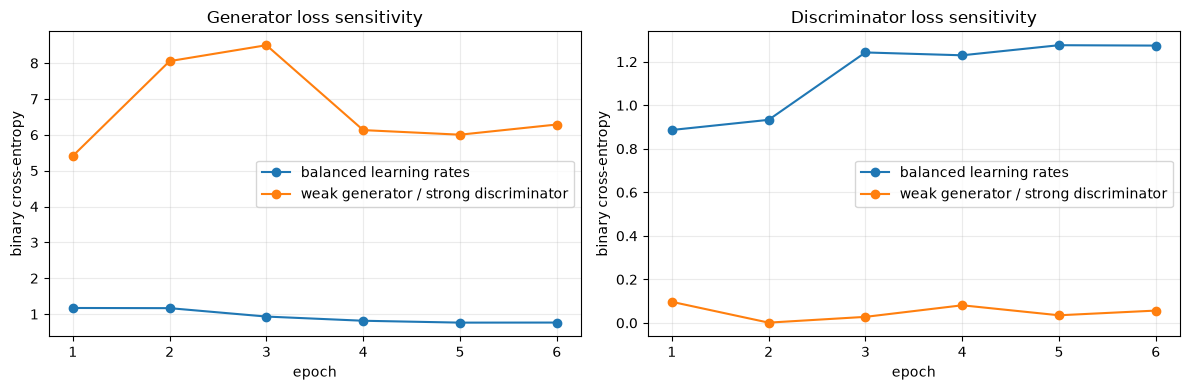

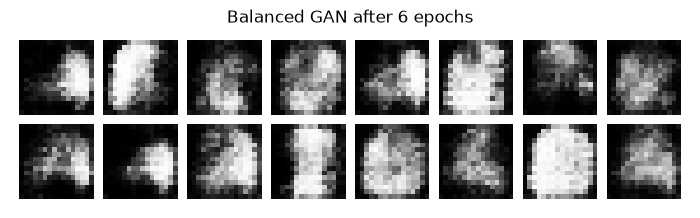

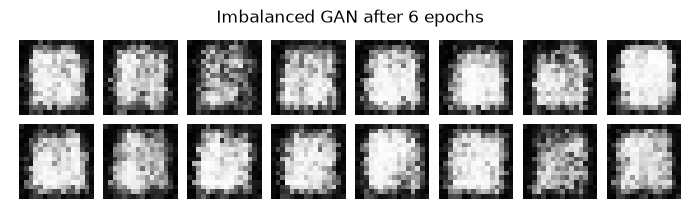

In [11]:
sensitive_generator = ConvolutionalGenerator().to(DEVICE)
sensitive_discriminator = ConvolutionalDiscriminator().to(DEVICE)

sensitive_history, sensitive_snapshots, _ = train_image_gan(
    sensitive_generator,
    sensitive_discriminator,
    training_loader,
    epochs=SENSITIVITY_EPOCHS,
    generator_learning_rate=5e-5,
    discriminator_learning_rate=1e-3,
)

comparison_epochs = np.arange(1, SENSITIVITY_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    comparison_epochs,
    gan_history["generator"][:SENSITIVITY_EPOCHS],
    marker="o",
    label="balanced learning rates",
)
axes[0].plot(
    comparison_epochs,
    sensitive_history["generator"],
    marker="o",
    label="weak generator / strong discriminator",
)
axes[0].set_title("Generator loss sensitivity")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("binary cross-entropy")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(
    comparison_epochs,
    gan_history["discriminator"][:SENSITIVITY_EPOCHS],
    marker="o",
    label="balanced learning rates",
)
axes[1].plot(
    comparison_epochs,
    sensitive_history["discriminator"],
    marker="o",
    label="weak generator / strong discriminator",
)
axes[1].set_title("Discriminator loss sensitivity")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("binary cross-entropy")
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

show_image_grid(
    gan_snapshots[SENSITIVITY_EPOCHS],
    f"Balanced GAN after {SENSITIVITY_EPOCHS} epochs",
    rows=2,
    columns=8,
)
show_image_grid(
    sensitive_snapshots[SENSITIVITY_EPOCHS],
    f"Imbalanced GAN after {SENSITIVITY_EPOCHS} epochs",
    rows=2,
    columns=8,
)

## 8. Interpolation

Interpolation tests whether nearby input points produce gradual output changes.

For the GAN, we interpolate between two latent vectors. For rectified flow, we interpolate between two initial noise vectors and run the complete sampling trajectory from each intermediate point.

A smooth visual transition suggests that the learned mapping is locally structured. It does not prove that every intermediate image is realistic.

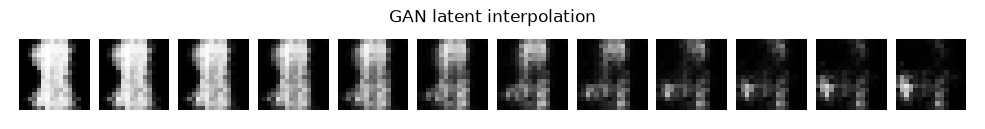

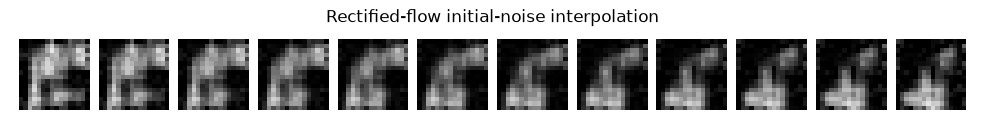

In [14]:
@torch.no_grad()
def linear_interpolation(start, end, count=12):
    weights = torch.linspace(0.0, 1.0, count, device=start.device)
    shape = (count,) + (1,) * start.ndim
    return (1.0 - weights.reshape(shape)) * start + weights.reshape(shape) * end


gan_start = sample_latent(1, LATENT_DIM, device=DEVICE).squeeze(0)
gan_end = sample_latent(1, LATENT_DIM, device=DEVICE).squeeze(0)
gan_interpolation_latent = linear_interpolation(gan_start, gan_end, count=12)
gan_interpolation = generate_gan_images(gan_generator, gan_interpolation_latent)

flow_start = torch.randn(DATA_DIM, device=DEVICE)
flow_end = torch.randn(DATA_DIM, device=DEVICE)
flow_interpolation_noise = linear_interpolation(flow_start, flow_end, count=12)
flow_interpolation = generate_flow_images(
    flow_model,
    flow_interpolation_noise,
    steps=FLOW_SAMPLING_STEPS,
).clamp(-1.0, 1.0)

show_image_grid(gan_interpolation, "GAN latent interpolation", rows=1, columns=12)
show_image_grid(
    flow_interpolation,
    "Rectified-flow initial-noise interpolation",
    rows=1,
    columns=12,
)

## 9. How these small models connect to larger systems

This notebook isolates the central sampling contrast:

- GAN: one learned mapping transforms noise directly into an image.
- Rectified flow: an iterative learned vector field transforms noise into an image.

Larger diffusion and flow systems keep the iterative idea but often operate in a compressed latent space rather than directly on pixels. Latent diffusion first encodes an image into a lower-dimensional representation, performs iterative generation there, and decodes the result.

Diffusion Transformers replace or supplement convolutional denoisers with Transformer blocks. Text-conditioned systems encode a prompt and let the image model use that representation, commonly through cross-attention. Classifier-free guidance changes how strongly sampling follows the condition. Distillation can reduce the number of iterative sampling steps.

Implementing those complete systems here would hide the basic comparison under substantial engineering and compute requirements, so they remain conceptual connections.

## 10. Reflection

1. Which model produced more recognizable clothing shapes?

   **Answer:** The GAN samples were slightly sharper and more recognizable; flow samples were often noisier.

2. Which model showed greater useful diversity, rather than merely greater numerical spread?

   **Answer:** The GAN showed slightly clearer useful diversity, although both had similar spread statistics.

3. Did the GAN loss curves correspond directly to improving images? Why should GAN losses be interpreted cautiously?

   **Answer:** No. GAN losses describe a changing competition, so lower loss does not directly mean better images.

4. How did the imbalanced learning-rate experiment change the losses and samples?

   **Answer:** The discriminator dominated, generator loss became very high, and samples collapsed toward similar bright shapes.

5. Approximately how much slower was iterative rectified-flow sampling than one-pass GAN sampling on your device?

   **Answer:** About 99 times slower: 142.1 ms versus 1.4 ms for 256 images.

6. Were either model's interpolations smooth? Where did ambiguous or unrealistic intermediate images appear?

   **Answer:** Both changed smoothly, but some middle images were ambiguous mixtures of the endpoints.

7. Which model seemed more sensitive to hyperparameters or training balance?

   **Answer:** The GAN was more sensitive because its two networks must remain balanced.

8. What are the main limitations of this comparison?

   **Answer:** Small 16 × 16 images, short training, unequal model sizes, and no perceptual quality metric.
